In [ ]:
import sys, os
sys.path.append(os.path.abspath(".."))
import pandas as pd
from src.io_utils import load_data

# Hämtar in data med load_data
sales_list = load_data("../data//ecommerce_sales.csv")
# Gör om datalistan till en dataframe
df = pd.DataFrame(sales_list)

# Kontrollerar värdena i dataframen
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   str    
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(1), str(4)
memory usage: 136.8 KB


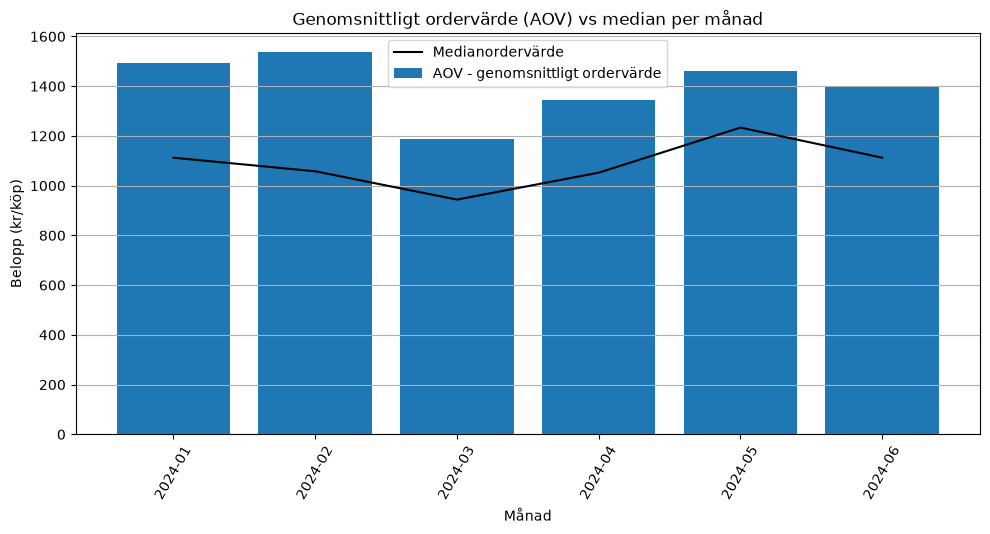

AOV för de första sex månaderna 2024 är: 1401 kr.
Medianen för de första sex månaderna 2024 är: 1089 kr.


In [ ]:
import matplotlib.pyplot as plt
from src import viz as v
from src import metrics as M

# Ändrar på formatet på kolumnen "date" i dataframen. Frå sträng till datumsformat.
df["date"] = pd.to_datetime(df["date"])
# Grupperar datan i kolumnen "revenue" per månad och räknar ut medel (AOV) och median för varje månad.
monthly_stats = df.groupby(df["date"].dt.to_period("M"))["revenue"].agg(
    ["mean", 
     "median"])

# Formen för diagrammet initieras
fig, ax = plt.subplots(figsize=(10, 5))
# Skickar datan till funktionen som ska rita diagrammen
v.plot_monthly_data(ax, monthly_stats)

plt.show()

# Här presenteras resultatet för aov och median för hela datamängden.
print(f"AOV för de första sex månaderna 2024 är: {M.average_order_value(sales_list):.0f} kr.")
print(f"Medianen för de första sex månaderna 2024 är: {M.calc_median(sales_list):.0f} kr.")
